In [1]:
import numpy as np
import pandas as pd
import regresija_fje as rf

In [3]:
# Učitavanje podataka iz CSV datoteke
data = pd.read_csv("data/data_hw1_2026.csv", header=None)
data = data.rename(columns={0: "x1", 1: "x2", 2: "y"})

X = data[["x1", "x2"]].values
y = data["y"].values

print(f"Dimenzije učitanih podataka: X = {X.shape}, y = {y.shape}")

Dimenzije učitanih podataka: X = (200, 2), y = (200,)


In [4]:
print(data.columns)# Definisanje prostora pretrage hiperparametara
degrees = [1, 2, 3, 4]              # Stepeni polinoma za testiranje
#lambdas = [0.001, 0.01, 0.1, 1.0, 10.0] # Vrednosti regularizacionog parametra lambda
#lambdas = [1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7]
lambdas = [0.0001, 0.001, 0.01, 0.1, 1.0, 2.0, 3.0]
k_folds = 5                         # Broj foldova za K-fold unakrsnu validaciju

print("Pokretanje K-fold unakrsne validacije za izbor hiperparametara...")
best_rmse = float('inf')
best_p = None
best_lambda = None

# Matrica za čuvanje RMSE rezultata
rmse_results = np.zeros((len(degrees), len(lambdas)))

for i, p in enumerate(degrees):
    for j, lmbda in enumerate(lambdas):
        avg_rmse = rf.cross_validation_kfold(X, y, k_folds, p, lmbda)
        rmse_results[i, j] = avg_rmse
        print(f"Stepen p = {p}, Lambda = {lmbda} | Prosečni RMSE = {avg_rmse:.4f}")

        if avg_rmse < best_rmse:
            best_rmse = avg_rmse
            best_p = p
            best_lambda = lmbda

print("\n--------------------------------------------------")
print(f"REZULTATI UNAKRSNE VALIDACIJE:")
print(f"  • Optimalni stepen polinoma (p): {best_p}")
print(f"  • Optimalna vrednost lambda (λ): {best_lambda}")
print(f"  • Minimalni prosečni RMSE:       {best_rmse:.4f}")
print("--------------------------------------------------")

Index(['x1', 'x2', 'y'], dtype='str')
Pokretanje K-fold unakrsne validacije za izbor hiperparametara...
Stepen p = 1, Lambda = 0.0001 | Prosečni RMSE = 2.2069
Stepen p = 1, Lambda = 0.001 | Prosečni RMSE = 2.2068
Stepen p = 1, Lambda = 0.01 | Prosečni RMSE = 2.2057
Stepen p = 1, Lambda = 0.1 | Prosečni RMSE = 2.1976
Stepen p = 1, Lambda = 1.0 | Prosečni RMSE = 2.4030
Stepen p = 1, Lambda = 2.0 | Prosečni RMSE = 2.6615
Stepen p = 1, Lambda = 3.0 | Prosečni RMSE = 2.6615
Stepen p = 2, Lambda = 0.0001 | Prosečni RMSE = 1.6745
Stepen p = 2, Lambda = 0.001 | Prosečni RMSE = 1.6743
Stepen p = 2, Lambda = 0.01 | Prosečni RMSE = 1.6731
Stepen p = 2, Lambda = 0.1 | Prosečni RMSE = 1.6772
Stepen p = 2, Lambda = 1.0 | Prosečni RMSE = 2.2527
Stepen p = 2, Lambda = 2.0 | Prosečni RMSE = 2.6615
Stepen p = 2, Lambda = 3.0 | Prosečni RMSE = 2.6615
Stepen p = 3, Lambda = 0.0001 | Prosečni RMSE = 1.5355
Stepen p = 3, Lambda = 0.001 | Prosečni RMSE = 1.5346
Stepen p = 3, Lambda = 0.01 | Prosečni RMSE = 1

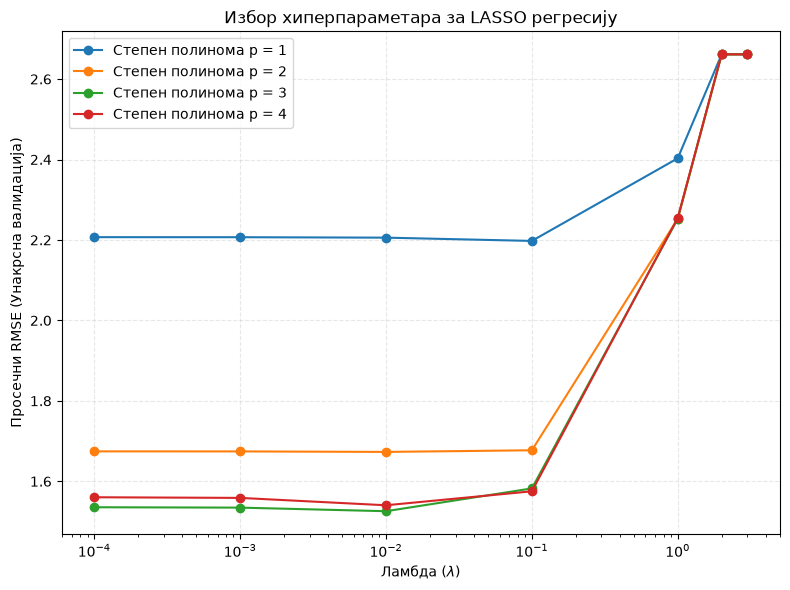

In [5]:
# Vizuelizacija izbora hiperparametara (za izveštaj) i čuvanje grafika
rf.plot_hyperparameter_selection(lambdas, degrees, rmse_results, name="Hiperparametri_rmse.pdf")

In [6]:
# Ručno odabiranje željenog stepena poilinoma i faktora regularizacije
#best_p = 3
#best_lambda = 0.01

NAUČENI PARAMETRI HIPOTEZE:
  • Slobodni član (b): -0.317600
  • Težinski koeficijenti (w): [ 2.86612303  0.         -0.20806685  0.8159117  -1.18051095 -1.65286645
  0.07121233  0.01631926  0.04015235]

DODATNE EVALUACIONE METRIKE MODELA:
  • Konačni RMSE na celom skupu: 1.4506
  • Konačni MAE na celom skupu:  1.1571
  • R² koeficijent determinacije: 0.7041

[INFO] Rezultati predikcija su uspešno sačuvani u 'data/lasso_rezultati_predikcije.csv'.



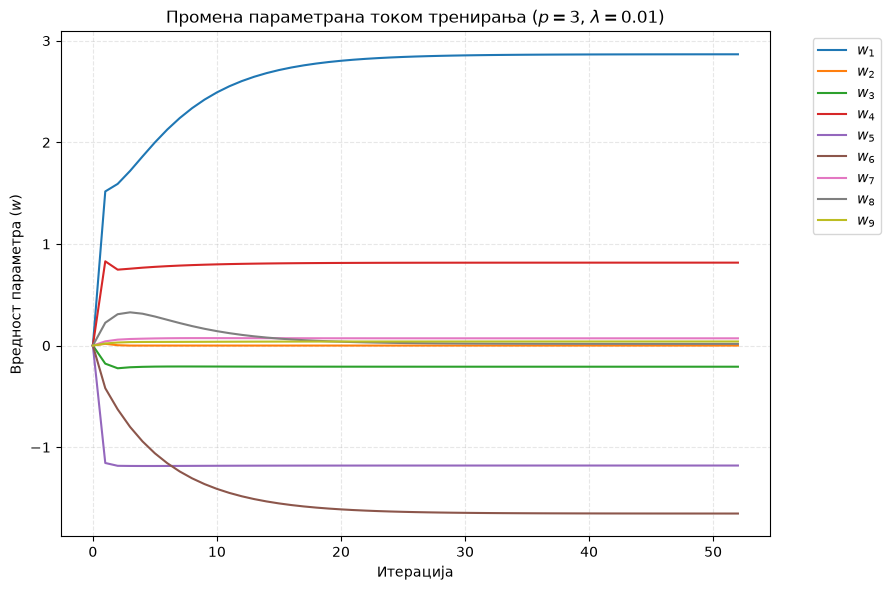

In [7]:
# Rezultati sa izabranim hiperparametrima
lasso_results = rf.train_and_evaluate_lasso(
    X=X,
    y=y,
    best_p=best_p,
    best_lambda=best_lambda,
    csv_path="data/lasso_rezultati_predikcije.csv",
    history_plot_name="param_history.pdf",
)

w = lasso_results['w']
b = lasso_results['b']
mean = lasso_results['mean']
std = lasso_results['std']
y_pred = lasso_results['y_pred']

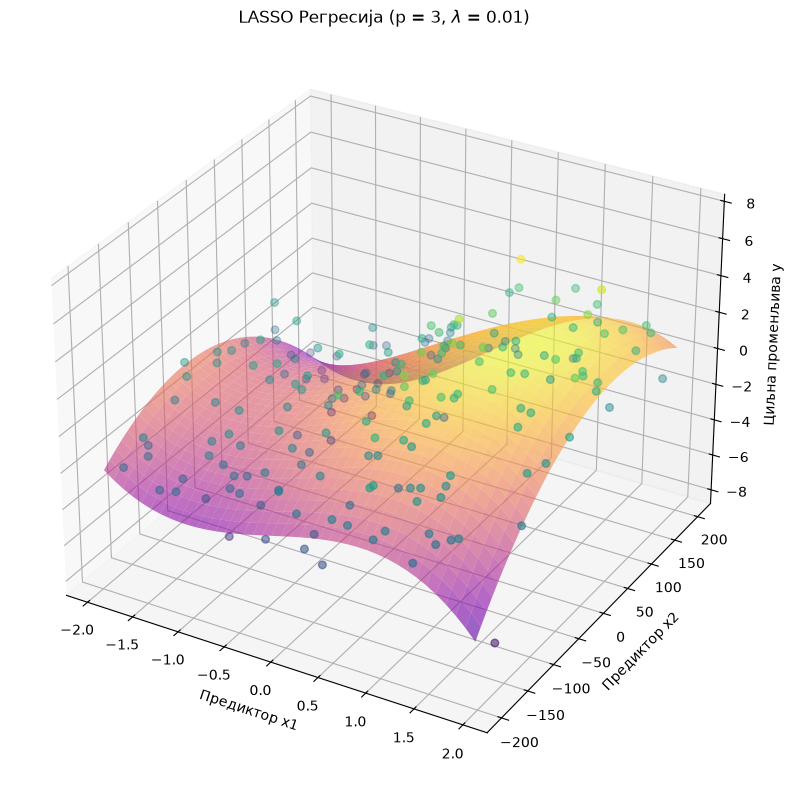

In [8]:
# 3d prikaz modela
rf.plot_lasso_3d_surface(
    X=X,
    y=y,
    w=w,
    b=b,
    mean=mean,
    std=std,
    best_p=best_p,
    best_lambda=best_lambda,
    name="lasso_3d_prikaz.pdf",
)

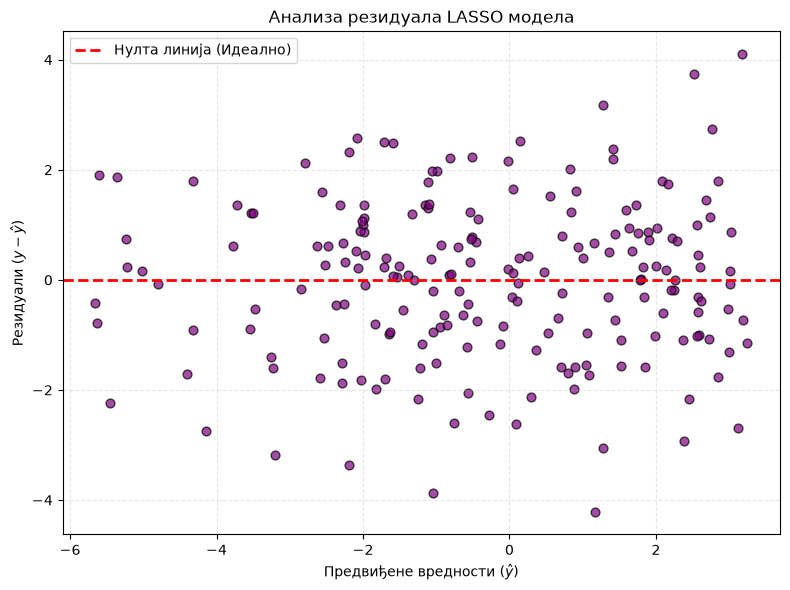

In [9]:
# Vizuelizacija i čuvanje reziduala
rf.plot_lasso_residuals(
    y=y,
    y_pred=y_pred,
    name="lasso_reziduali_analiza.pdf",
)

In [10]:
# Interaktivni 3D prikaz LASSO modela
fig_3d = rf.plot_interactive_lasso_3d(
    X=X,
    y=y,
    w=w,
    b=b,
    mean=mean,
    std=std,
    best_p=best_p,
    best_lambda=best_lambda,
    name="interaktivna_lasso_3d.html",
)

[INFO] Interaktivni grafik je uspešno sačuvan kao 'interaktivna_lasso_3d.html'.
